In [1]:
#터미널에 pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132

In [2]:
import torch
print(torch.cuda.is_available())        # True면 성공
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 5060 Laptop GPU


In [3]:
#cmd -> 관리자권한실행 -> nvidia-smi 실행 -> 드라이버 설치되어있는지 ->없으면 엔비디아 확인 

In [4]:
print(torch.version.cuda)

13.2


In [5]:
import torch
print(torch.cuda.device_count())

1


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [7]:
iris = load_iris()
iris 

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [8]:
iris.target_names


array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [9]:
iris.target[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [10]:
#데이터분할 작업 
X_train, X_test, y_train, y_test = train_test_split(
    iris.data,iris.target, test_size=0.2, random_state=42, stratify=iris.target
)
#8:2비율로 추출


In [11]:
scaler=StandardScaler()
X_train_tensor=torch.FloatTensor(scaler.fit_transform(X_train))
#텐서를 파이토치형으로 변환시켜줘야함 
X_test_tensor=torch.FloatTensor(scaler.transform(X_test))
y_train_tensor=torch.LongTensor(y_train)
y_test_tensor=torch.LongTensor(y_test)

In [12]:
class IrisNet(nn.Module):
    #신경망 클래스 만들때 기본모듈
    def __init__(self):
        super().__init__()
        self.layers=nn.Sequential(
            nn.Linear(4,16),
            nn.ReLU(),
            nn.Linear(16,3)
        )
    def forward(self,x):
        return self.layers(x)

In [13]:
model = IrisNet() #모델 객체 생성
criterion = nn.CrossEntropyLoss() #손실함수 정의
optimizer = optim.Adam(model.parameters(),lr=0.01) #최적화 함수

In [14]:
for _ in range(100):
    optimizer.zero_grad()
    loss=criterion(model(X_train_tensor),y_train_tensor)
    #손실값 계산
    loss.backward()
    #손실값에 따른 기울기(가중치 계산)
    optimizer.step()
    #기울기와 편향 수정

In [15]:
model.eval()
with torch.no_grad():
    pred=model(X_test_tensor).argmax(dim=1)
    acc=(pred==y_test_tensor).float().mean()
    print(f"테스트 정확도: {acc*100:.2f}%")
    for i in range(3):
        print(f"실제: {iris.target_names[y_test[i]]}, 예측: {iris.target_names[pred[i].item()]}")


테스트 정확도: 96.67%
실제: setosa, 예측: setosa
실제: virginica, 예측: virginica
실제: versicolor, 예측: versicolor


In [16]:
for _ in range(100):
    model.train()
    #학습모드로 전환 가중치없음 
    loss=criterion(model(X_train_tensor),y_train_tensor)
    #손실값 계산
    loss.backward()
    #손실값에 따른 기울기(가중치 계산)
    optimizer.step()
    #기울기와 편향 수정

In [17]:
model.eval() #평가모드로 전환 
with torch.no_grad(): #no_Grad() 가중치(기울기) 계산 비활성화
    pred=model(X_test_tensor).argmax(dim=1)
    acc=(pred==y_test_tensor).float().mean()
    print(f"테스트 정확도: {acc*100:.2f}%")
    for i in range(3):
        print(f"실제: {iris.target_names[y_test[i]]}, 예측: {iris.target_names[pred[i].item()]}")


테스트 정확도: 96.67%
실제: setosa, 예측: setosa
실제: virginica, 예측: virginica
실제: versicolor, 예측: versicolor


In [18]:
#보스턴집값

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader,TensorDataset

In [20]:
from sklearn.datasets import fetch_openml

boston=fetch_openml(name="boston",version=1,as_frame=True,parser="auto")
X=boston.data
y=boston.target

In [21]:
X.head(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.9,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.9,9.14


In [22]:
y[:10]

0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
5    28.7
6    22.9
7    27.1
8    16.5
9    18.9
Name: MEDV, dtype: float64

In [23]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [24]:
X_train,X_temp,y_train,y_temp = train_test_split(X_scaled,y,test_size=0.2,random_state=42)
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=42)

In [25]:
X_train = torch.FloatTensor(X_train)
y_train = torch.FloatTensor(y_train.values).view(-1,1)
X_val = torch.FloatTensor(X_val)
y_val = torch.FloatTensor(y_val.values).view(-1,1)
X_test = torch.FloatTensor(X_test)
y_test = torch.FloatTensor(y_test.values).view(-1,1)

In [26]:
from torch.utils.data import TensorDataset, DataLoader

#TensorDataset():입력데이터와 정답 데이터를 하나의 데이터셋으로 묶는다
train_dataset=TensorDataset(X_train,y_train)
#DataLoader():데이터를 모델에 전달하기 편리하도록 미니배치 단위로 나눈다.
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)

In [27]:
print(f"Train set:{X_train.shape}, Val set:{X_val.shape}, Test set:{X_test.shape}")


Train set:torch.Size([404, 13]), Val set:torch.Size([51, 13]), Test set:torch.Size([51, 13])


In [28]:
model = nn.Sequential(
    nn.Linear(13,64),
    nn.ReLU(),
    nn.Linear(64,32),
    nn.ReLU(),
    nn.Linear(32,1)
)
print(model)

Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


In [29]:
criterion=nn.MSELoss()
#MSELoss(): 회귀 (평균제곱오차, 집값처럼 연속된 숫자 예측)
#CrossEntropyLoss(): 다중분류 (모델 출력에 softmax 없이 그대로 넣음)
#BCELoss(): 이진분류 (모델 마지막에 Sigmoid를 넣어야 함, 0~1 확률값을 입력)
#BCEWithLogitsLoss(): 이진분류 (Sigmoid가 내장됨, 모델 출력을 그대로 넣음, BCELoss보다 계산이 안정적)

optimizer=optim.Adam(model.parameters(),lr=0.01)
#Adam: 가중치를 업데이트하는 최적화 함수
#model.parameters(): 학습할 가중치와 편향
#lr=0.01: 학습률 (한 번에 가중치를 얼마나 크게 바꿀지)

In [30]:
epochs=100
for epoch in range(epochs):
    model.train()
    for batch_X,batch_y in train_loader:
        optimizer.zero_grad()
        y_pred=model(batch_X)
        loss=criterion(y_pred,batch_y)
        loss.backward()
        optimizer.step()

    #검증
    model.eval()
    with torch.no_grad():
        val_pred=model(X_val)
        val_loss=criterion(val_pred,y_val)

    if (epoch+1)%10==0:
        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}")

Epoch 10/100, Train Loss: 28.1707, Val Loss: 18.7825
Epoch 20/100, Train Loss: 6.4423, Val Loss: 16.6383
Epoch 30/100, Train Loss: 3.5560, Val Loss: 17.4413
Epoch 40/100, Train Loss: 4.8366, Val Loss: 19.0156
Epoch 50/100, Train Loss: 8.9058, Val Loss: 19.4564
Epoch 60/100, Train Loss: 2.7234, Val Loss: 19.3885
Epoch 70/100, Train Loss: 5.6351, Val Loss: 19.1522
Epoch 80/100, Train Loss: 11.8227, Val Loss: 19.0428
Epoch 90/100, Train Loss: 5.7608, Val Loss: 19.6572
Epoch 100/100, Train Loss: 3.1232, Val Loss: 18.4688


In [31]:
#model test
#테스트데이터로 평가
print("\n 테스트 세트로 모델 평가 중...")
model.eval()
with torch.no_grad():
    test_pred = model(X_test)
    test_loss = criterion(test_pred,y_test)
    print(f"Test MSE Loss: {test_loss.item():.4f}")
    print(f"실제값(예시): {y_test[0].item():.2f}, 예측값: {test_pred[0].item():.2f}")

mae= torch.mean(torch.abs(test_pred-y_test))
print(f"Test MAE(오차평균): {mae.item():.4f}")


 테스트 세트로 모델 평가 중...
Test MSE Loss: 7.0500
실제값(예시): 23.10, 예측값: 23.73
Test MAE(오차평균): 1.9960


In [32]:
#GPU사용
#기존데이터를 gpu에서쓸수있도록 이동


In [33]:
#모델객체를 만들고 to devic로 옮겨줌 
#쿠다 체크는 라이브러리 만들고 체크해줌 -> 데이터로드 ->데이터 전처리 ->모델객체 만들고 이동시킴 -> 손실함수

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader,TensorDataset

In [35]:
device=torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("사용 장치",device)

if torch.cuda.is_available():
    print("GPU이름:",torch.cuda.get_device_name(0))

사용 장치 cuda
GPU이름: NVIDIA GeForce RTX 5060 Laptop GPU


In [36]:
from sklearn.datasets import fetch_openml

boston=fetch_openml(name="boston",version=1,as_frame=True,parser="auto")
X=boston.data
y=boston.target

In [37]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [38]:
X_train,X_temp,y_train,y_temp = train_test_split(X_scaled,y,test_size=0.2,random_state=42)
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=42)

In [39]:
X_train = torch.FloatTensor(X_train)
y_train = torch.FloatTensor(y_train.values).view(-1,1)
X_val = torch.FloatTensor(X_val)
y_val = torch.FloatTensor(y_val.values).view(-1,1)
X_test = torch.FloatTensor(X_test)
y_test = torch.FloatTensor(y_test.values).view(-1,1)

In [40]:
from torch.utils.data import TensorDataset, DataLoader

#TensorDataset():입력데이터와 정답 데이터를 하나의 데이터셋으로 묶는다
train_dataset=TensorDataset(X_train,y_train)
#DataLoader():데이터를 모델에 전달하기 편리하도록 미니배치 단위로 나눈다.
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)

In [41]:
model = nn.Sequential(
    nn.Linear(13,64),
    nn.ReLU(),
    nn.Linear(64,32),
    nn.ReLU(),
    nn.Linear(32,1)
).to(device)
#모델객체를 디바이스로옮겨줌
print(model)

Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


In [42]:
criterion=nn.MSELoss()
#MSELoss(): 회귀 (평균제곱오차, 집값처럼 연속된 숫자 예측)
#CrossEntropyLoss(): 다중분류 (모델 출력에 softmax 없이 그대로 넣음)
#BCELoss(): 이진분류 (모델 마지막에 Sigmoid를 넣어야 함, 0~1 확률값을 입력)
#BCEWithLogitsLoss(): 이진분류 (Sigmoid가 내장됨, 모델 출력을 그대로 넣음, BCELoss보다 계산이 안정적)

optimizer=optim.Adam(model.parameters(),lr=0.01)
#Adam: 가중치를 업데이트하는 최적화 함수
#model.parameters(): 학습할 가중치와 편향
#lr=0.01: 학습률 (한 번에 가중치를 얼마나 크게 바꿀지)

In [43]:
model=model.to(device)


epochs=100
for epoch in range(epochs):
    model.train()
    for batch_X,batch_y in train_loader:
        batch_X=batch_X.to(device)
        batch_y=batch_y.to(device)

        optimizer.zero_grad()
        y_pred=model(batch_X)
        loss=criterion(y_pred,batch_y)
        loss.backward()
        optimizer.step()

    #검증
    model.eval()
    X_val=X_val.to(device)
    y_val=y_val.to(device)
    with torch.no_grad():
        val_pred=model(X_val)
        val_loss=criterion(val_pred,y_val)

    if (epoch+1)%10==0:
        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}")

Epoch 10/100, Train Loss: 8.1879, Val Loss: 18.0271
Epoch 20/100, Train Loss: 10.8058, Val Loss: 17.6035
Epoch 30/100, Train Loss: 6.0995, Val Loss: 16.3624
Epoch 40/100, Train Loss: 7.4720, Val Loss: 16.9121
Epoch 50/100, Train Loss: 11.9584, Val Loss: 16.6999
Epoch 60/100, Train Loss: 7.2500, Val Loss: 17.3498
Epoch 70/100, Train Loss: 10.1824, Val Loss: 18.5915
Epoch 80/100, Train Loss: 5.6756, Val Loss: 17.3747
Epoch 90/100, Train Loss: 4.3134, Val Loss: 18.1232
Epoch 100/100, Train Loss: 4.4498, Val Loss: 17.5982


In [44]:
#model test
#테스트데이터로 평가
print("\n 테스트 세트로 모델 평가 중...")
X_test=X_test.to(device)
y_test=y_test.to(device)
model.eval()
with torch.no_grad():
    test_pred = model(X_test)
    test_loss = criterion(test_pred,y_test)
    print(f"Test MSE Loss: {test_loss.item():.4f}")
    print(f"실제값(예시): {y_test[0].item():.2f}, 예측값: {test_pred[0].item():.2f}")

mae= torch.mean(torch.abs(test_pred-y_test))
print(f"Test MAE(오차평균): {mae.item():.4f}")


 테스트 세트로 모델 평가 중...
Test MSE Loss: 6.2516
실제값(예시): 23.10, 예측값: 21.81
Test MAE(오차평균): 1.7484


In [45]:
#cnn모델 
#합성곱 신경망을 사용한 이미지 분류


In [46]:
import torch

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    #쿠다에서 사용가능하면 쿠다에서 시드설정
    torch.backends.cudnn.deterministic=True
    #동일한입력에대해서는 동일한결과가나오도록 설계하겠다.
    #최대한일뿐 강제적인건 X

In [47]:
from torchvision.datasets import FashionMNIST

fm_train = FashionMNIST(root=".",train=True,download=True)
fm_test=FashionMNIST(root=".",train=False,download=True)

In [48]:
train_input=fm_train.data
train_target=fm_train.targets

In [49]:
train_scaled=train_input.reshape(-1,1,28,28)/255

In [50]:
from sklearn.model_selection import train_test_split

train_scaled,val_scaled,train_target,val_target=train_test_split(
    train_scaled,train_target,test_size=0.2,random_state=42
)

In [ ]:
import torch.nn as nn
model=nn.Sequential()
model.add_module("conv1",nn.Conv2d(1,32,kernel_size=3,padding="same"))
#첫번째층에서 32개
model.add_module("relu1",nn.ReLU())
model.add_module("pool1",nn.MaxPool2d(2)) #14x14
model.add_module("conv2",nn.Conv2d(32,64,kernel_size=3,padding="same"))
#두번째층에서 64개
model.add_module("relu2",nn.ReLU())
model.add_module("pool2",nn.MaxPool2d(2))
#맥스풀링까지 두개
model.add_module("flatten",nn.Flatten())
#1차원구조로 변경


In [53]:
outputs=model(torch.ones(1,1,28,28))
print(outputs.shape)

torch.Size([1, 3136])


In [54]:
model.add_module("dense1",nn.Linear(3136,100))
model.add_module("relu3",nn.ReLU())
model.add_module("dropout",nn.Dropout(0.3))
model.add_module("dense2",nn.Linear(100,10))

In [55]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

Sequential(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense1): Linear(in_features=3136, out_features=100, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (dense2): Linear(in_features=100, out_features=10, bias=True)
)

In [56]:
import torch.optim as optim
criterion=nn.CrossEntropyLoss() #다중분류
optimizer=optim.Adam(model.parameters())

In [58]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset=TensorDataset(train_scaled,train_target)
val_dataset=TensorDataset(val_scaled,val_target)

train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=32,shuffle=False)

In [59]:
train_hist=[]
val_hist=[]
patience=2
best_loss=-1
early_stopping_counter=0

epochs=20
for epoch in range(epochs):
    model.train()
    train_loss=0
    for inputs,targets in train_loader:
        inputs,targets=inputs.to(device),targets.to(device)
        optimizer.zero_grad()
        outputs=model(inputs)
        loss=criterion(outputs,targets)
        loss.backward()
        optimizer.step()
        train_loss+=loss.item()

    model.eval()
    val_loss=0
    with torch.no_grad():
        for inputs,targets in val_loader:
            inputs,targets=inputs.to(device),targets.to(device)
            outputs=model(inputs)
            loss=criterion(outputs,targets)
            val_loss+=loss.item()

    train_loss=train_loss/len(train_loader)
    val_loss=val_loss/len(val_loader)
    train_hist.append(train_loss)
    val_hist.append(val_loss)
    print(f"에포크:{epoch+1}, 훈련손실:{train_loss:.4f}, 검증손실:{val_loss:.4f}")

    if best_loss==-1 or val_loss<best_loss:
        best_loss=val_loss
        early_stopping_counter=0
        torch.save(model.state_dict(),"best_cnn_model.pt")
    else:
        early_stopping_counter+=1
        if early_stopping_counter>=patience:
            print(f"{epoch+1}번째 에포크에서 조기 종료되었습니다.")
            break

에포크:1, 훈련손실:0.5197, 검증손실:0.3430
에포크:2, 훈련손실:0.3420, 검증손실:0.3001
에포크:3, 훈련손실:0.2896, 검증손실:0.2620
에포크:4, 훈련손실:0.2614, 검증손실:0.2399
에포크:5, 훈련손실:0.2344, 검증손실:0.2367
에포크:6, 훈련손실:0.2151, 검증손실:0.2440
에포크:7, 훈련손실:0.1977, 검증손실:0.2220
에포크:8, 훈련손실:0.1795, 검증손실:0.2200
에포크:9, 훈련손실:0.1658, 검증손실:0.2205
에포크:10, 훈련손실:0.1508, 검증손실:0.2353
10번째 에포크에서 조기 종료되었습니다.


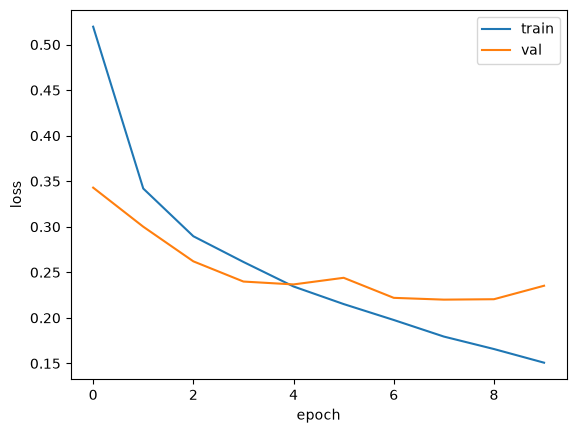

In [61]:
import matplotlib.pyplot as plt

plt.plot(train_hist,label="train")
plt.plot(val_hist,label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [62]:
#저장된 모델을 불러 오는 방법
model.load_state_dict(torch.load("best_cnn_model.pt",weights_only=True))

<All keys matched successfully>

In [ ]:
test_scaled=fm_test.data.reshape(-1,1,28,28)/255.0
#스케일링
test_target=fm_test.targets

test_dataset=TensorDataset(test_scaled,test_target)
test_loader=DataLoader(test_dataset,batch_size=32,shuffle=False)

model.eval()
corrects=0
with torch.no_grad():
    for inputs,targets in test_loader:
        inputs,targets=inputs.to(device),targets.to(device)
        outputs=model(inputs)
        predicts=torch.argmax(outputs,1)
        corrects+=(predicts==targets).sum().item()

accuracy=corrects/len(test_dataset)
print(f"테스트 정확도: {accuracy:.4f}")

테스트 정확도: 0.9135
